# Medical Insurance Charges: Exploratory Data Analysis

**Tools:** Python · Pandas · Seaborn · Matplotlib  
**Project origin:** Independently consolidated and revised from my school Python Assignments 4 and 5.  
**Objective:** Investigate how BMI, age, smoking status, and geography relate to reported insurance charges. This is descriptive exploration, not causal analysis or price prediction.

### Questions
1. How are records distributed across regions?
2. What patterns appear between BMI, age, and charges?
3. Does smoking status help explain the high-charge clusters?
4. Which numeric variables have stronger linear relationships with charges?

## 1. Load and inspect the data

Download `insurance.csv` from the [Medical Cost Personal Dataset on Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance) or from the Kaggle dataset used in the original assignment, and put it in this repository's `data/` folder. The notebook also recognizes the original Kaggle notebook path. Run the notebook with the repository as your working folder, or directly from `notebooks/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
paths = [
    Path("data/insurance.csv"),
    Path("../data/insurance.csv"),
    Path("/kaggle/input/datasets/thedatawizard/insurance/insurance.csv"),
    Path("/kaggle/input/insurance/insurance.csv"),
]
source = next((p for p in paths if p.exists()), None)
if source is None:
    raise FileNotFoundError(
        "Download insurance.csv (see README) and save it under data/insurance.csv. "
        "Then rerun the notebook."
    )
df = pd.read_csv(source)
print(f"Loaded {len(df):,} rows from {source}")
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Loaded 1,338 rows from ../data/insurance.csv


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
print("Shape:", df.shape)
df.info()
display(df.describe())
display(df.isna().sum().rename("missing_values").to_frame())
print("Duplicate rows:", df.duplicated().sum())

Shape: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


,missing_values
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


Duplicate rows: 1


**Data-quality note:** The original assignments used `info()` and `describe()` to examine non-null counts, column types, and numerical summary statistics. Here I also explicitly check missing and duplicated rows. Duplicates are *reported rather than automatically deleted*: identical-looking rows could be valid observations without a unique policy identifier.

In [3]:
required = {"age", "sex", "bmi", "children", "smoker", "region", "charges"}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns not found: {sorted(missing_columns)}")
assert pd.api.types.is_numeric_dtype(df["charges"]), "charges must be numeric"
assert pd.api.types.is_numeric_dtype(df["bmi"]), "bmi must be numeric"
assert pd.api.types.is_numeric_dtype(df["age"]), "age must be numeric"

## 2. Regional distribution

**Original work retained:** Counting observations by region. **Correction:** An observation represents a dataset record; it cannot be described as a purchase without transaction data. Regions are categories, so a bar plot—not a connected line chart—is appropriate.

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


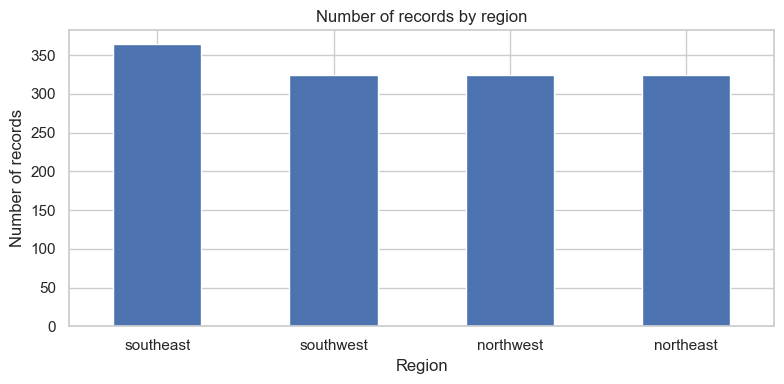

In [4]:
region_counts = df["region"].value_counts().sort_values(ascending=False)
print(region_counts)
ax = region_counts.plot.bar(figsize=(8, 4), title="Number of records by region")
ax.set(xlabel="Region", ylabel="Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation prompt:** Identify which region has the most records, but do not claim that this reflects insurance demand or purchasing activity. The dataset does not establish that.

## 3. BMI and medical charges

**Original insight retained:** Plotting every unique BMI as a separate bar makes a crowded, difficult-to-read figure. A scatterplot better supports examining BMI against continuous charges.

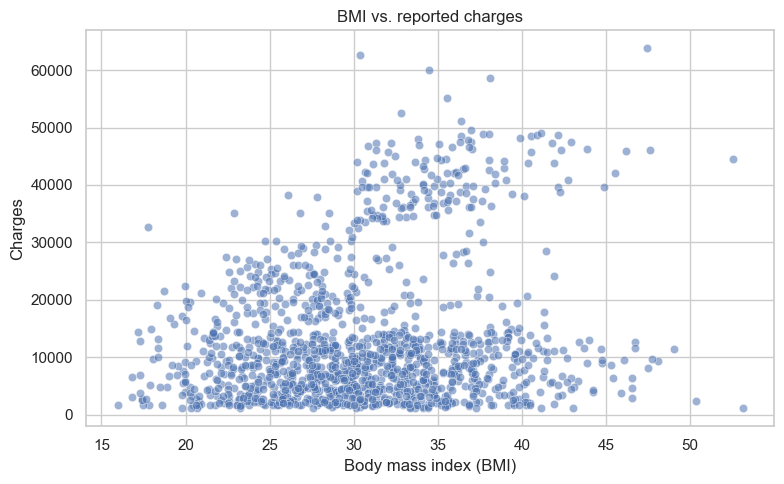

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="bmi", y="charges", alpha=.55, ax=ax)
ax.set(title="BMI vs. reported charges", xlabel="Body mass index (BMI)", ylabel="Charges")
plt.tight_layout()
plt.show()

**Observation from original Assignment 4:** A high-charge cluster appeared among records with BMI roughly 30–40. That motivated checking whether another variable—smoking status—helps explain the pattern. A scatterplot alone does not establish causation.

## 4. Age and medical charges

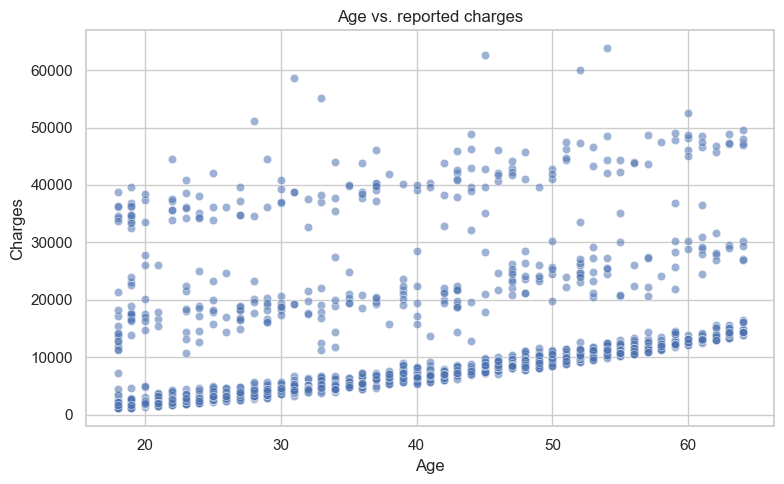

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="age", y="charges", alpha=.55, ax=ax)
ax.set(title="Age vs. reported charges", xlabel="Age", ylabel="Charges")
plt.tight_layout()
plt.show()

**Original interpretation, refined:** Charges tend to show higher values at older ages, although the plot contains broad variation. Avoid describing the relationship as universally direct for every person.

## 5. Add smoking status to explain high-charge patterns

This extends the original BMI scatterplot with `hue="smoker"` and retains the later age-versus-charges plot colored by smoking status.

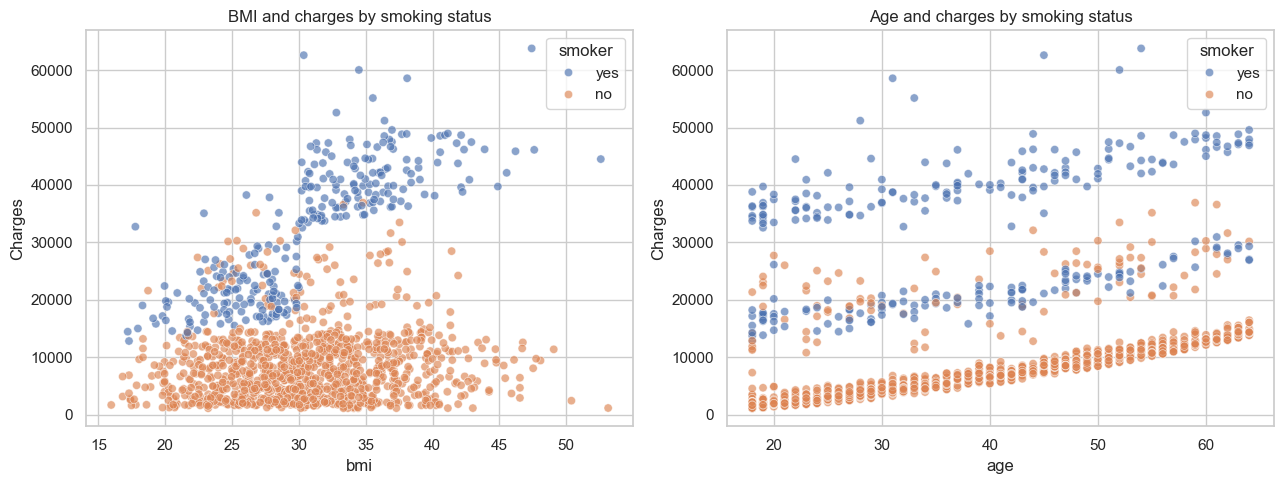

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=.65, ax=axes[0])
axes[0].set(title="BMI and charges by smoking status")
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=.65, ax=axes[1])
axes[1].set(title="Age and charges by smoking status")
for ax in axes:
    ax.set(ylabel="Charges")
plt.tight_layout()
plt.show()

**Finding from the original work:** Smoking status visually distinguishes many high-charge observations and helps explain why BMI alone looked inconclusive. This is an association in the sample, not proof that smoking causes a specific charge increase.

## 6. Quantify differences without inventing causes

Summarize observed charges across smoking groups and estimate *within-group* correlations of BMI and charges. These descriptive summaries complement the visual plots.

In [8]:
smoker_summary = (df.groupby("smoker", observed=True)["charges"]
                  .agg(records="count", mean_charges="mean", median_charges="median")
                  .round(2))
display(smoker_summary)

within_group_bmi_corr = df.groupby("smoker").apply(
    lambda group: group["bmi"].corr(group["charges"]),
    include_groups=False
).rename("bmi_charges_pearson_r")
display(within_group_bmi_corr.round(3).to_frame())

,records,mean_charges,median_charges
smoker,,,
no,1064,8434.27,7345.41
yes,274,32050.23,34456.35


,bmi_charges_pearson_r
smoker,
no,0.084
yes,0.806


## 7. Correlation analysis

**Original Assignment 5 retained:** Use a correlation matrix and Seaborn heatmap. **Correction:** Coding `region` as 0, 1, 2, 3 creates an arbitrary numerical order. Use meaningful numeric fields, plus a documented binary indicator for smoking, rather than taking Pearson correlations on arbitrary region codes. Region and sex are not encoded as continuous measurements.

,age,bmi,children,charges,is_smoker
age,1.000,0.109,0.042,0.299,-0.025
bmi,0.109,1.000,0.013,0.198,0.004
children,0.042,0.013,1.000,0.068,0.008
charges,0.299,0.198,0.068,1.000,0.787
is_smoker,-0.025,0.004,0.008,0.787,1.000


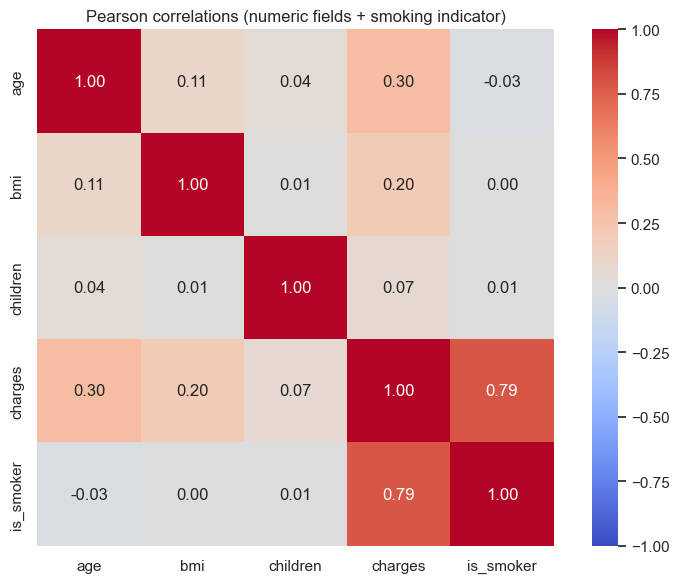

In [9]:
numeric = df[["age", "bmi", "children", "charges"]].copy()
numeric["is_smoker"] = df["smoker"].map({"no": 0, "yes": 1})
if numeric["is_smoker"].isna().any():
    raise ValueError("Unexpected smoking-status values found")
corr = numeric.corr(numeric_only=True)
display(corr.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, annot=True, fmt=".2f", ax=ax)
ax.set_title("Pearson correlations (numeric fields + smoking indicator)")
plt.tight_layout()
plt.show()

**Interpretation of the change:** The original notebook found a negative correlation between its `smoker` code and `charges` because it coded `yes=0` and `no=1`. The revised indicator uses `yes=1` and `no=0`, so the sign reverses, **without changing the underlying relationship**. Correlations do not adjust for confounders or establish cause and effect.

## 8. Conclusion and next steps

The original assignments led from a visual BMI question to considering smoking status as a major grouping variable. This consolidated notebook preserves that investigation while adding quality checks and more defensible interpretations.

**Actionable analytical next steps:**
- Compare BMI–charge patterns *within* smoking-status groups rather than inferring from the pooled scatterplot alone.
- Check whether differences persist across age brackets with stratified summaries.
- Treat this dataset as an exploratory educational example, not as a basis for real insurance underwriting or individual pricing decisions.

**Limitations:** The data is observational, includes no clear sampling methodology here, and reports billed charges—not proof of what an insurer paid or an individual owed. No predictive model or causal estimate was produced.

**Attribution:** Based on Christopher Moore's original school Assignments 4 and 5, independently reorganized and revised for a portfolio. Dataset source credited in README.